#Modelo de Propensão à Contratação para CRM Bancário

##1. Contexto e objetivo de negócio

Este projeto foi desenvolvido no contexto de um desafio para a posição de Pesquisador de Dados em CRM bancário. O objetivo é investigar como técnicas de análise de dados e Machine Learning podem apoiar a priorização de clientes em campanhas comerciais.

Para o estudo, foi utilizada a base pública Bank Marketing, disponibilizada pelo repositório UCI Machine Learning Repository. O conjunto contém registros históricos de campanhas de marketing de um banco português, cujo objetivo era a contratação de depósitos a prazo.

A proposta consiste em estimar a probabilidade de contratação a partir de características dos registros disponíveis antes do contato, ordenar os registros por propensão estimada e avaliar o desempenho dessa priorização.

###Pergunta de negócio

Como utilizar dados históricos para identificar registros com maior propensão estimada à contratação e, assim, apoiar decisões de priorização em campanhas de CRM?

###Escopo do experimento

A análise compara modelos de classificação e investiga diferentes estratégias de seleção de registros. A seleção dos 2.000 registros mais bem classificados é utilizada como cenário experimental de capacidade operacional, e não como uma campanha real.

A base é pública e não contém identificadores reais de clientes que permitam executar contatos comerciais. Portanto, os resultados representam uma avaliação metodológica, e não uma lista operacional de clientes de um banco.


# 02. Preparação do ambiente, carregamento e análise exploratória 

In [0]:
%sql
-- Criação de schema e volume para armazenamento dos dados. 
CREATE SCHEMA IF NOT EXISTS workspace.crm_propensao
COMMENT 'Projeto de modelagem de propensão para CRM';

CREATE VOLUME IF NOT EXISTS workspace.crm_propensao.dados_fonte
COMMENT 'Armazenamento dos arquivos de dados originais do projeto CRM';

In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Bibliotecas e Imports 

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql.types import *
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

In [0]:
# Dados. 

caminho_arquivo = "/Volumes/workspace/crm_propensao/dados_fonte/bank-full.csv"

df = (
    spark.read
    .option("header", True)
    .option("sep", ";")
    .option("inferSchema", True)
    .csv(caminho_arquivo)
)

print(f"Quantidade de registros: {df.count()}")
print(f"Quantidade de colunas: {len(df.columns)}")

#display(df.limit(5))

Quantidade de registros: 45211
Quantidade de colunas: 17


### Etapa 2. Análise Exploratória dos Dados (EDA)

### Etapa 2. Análise Exploratória dos Dados 



In [0]:
#Análise de dados faltantes
nulos = df.select([F.count(F.when(F.col(c).isNull() | (F.isnan(c) if dict(df.dtypes)[c] != 'string' else F.lit(False)), c)).alias(c) for c in df.columns])

nulos.show()

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|  0|  0|      0|        0|      0|      0|      0|   0|      0|  0|    0|       0|       0|    0|       0|       0|  0|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+



In [0]:
# Conta o total de linhas
total_linhas = df.count()

# Conta o total de linhas únicas
total_linhas_unicas = df.distinct().count()

# Calcula a diferença
total_duplicadas = total_linhas - total_linhas_unicas

print(f"Total de registros na base: {total_linhas}")
print(f"Total de registros únicos: {total_linhas_unicas}")
print(f"Quantidade de linhas totalmente duplicadas: {total_duplicadas}")


Total de registros na base: 45211
Total de registros únicos: 45211
Quantidade de linhas totalmente duplicadas: 0


In [0]:
#Análise das variáveis age (idade) e  balance (saldo médio anual).
df.select(
    F.min("age").alias("Idade Mínima"),
    F.max("age").alias("Idade Máxima"),
    F.avg("age").alias("Idade Média"),
    F.stddev("age").alias("Desvio Padrão Idade"),
    F.min("balance").alias("Saldo Mínimo"),
    F.max("balance").alias("Saldo Máximo"),
    F.avg("balance").alias("Saldo Médio"),
    F.stddev("balance").alias("Desvio Padrão Saldo")
).display()

Idade Mínima,Idade Máxima,Idade Média,Desvio Padrão Idade,Saldo Mínimo,Saldo Máximo,Saldo Médio,Desvio Padrão Saldo
18,95,40.93621021432837,10.618762040975422,-8019,102127,1362.2720576850766,3044.7658291684934


In [0]:
#Análise gráfica com box plot das variáveis age (idade) e  balance (saldo médio anual).

# Selecionar a variável
coluna = 'age'

# Calcular os quartis e o IQR
Q1 = df.select(F.expr(f"percentile({coluna}, 0.25)")).collect()[0][0]
Q3 = df.select(F.expr(f"percentile({coluna}, 0.75)")).collect()[0][0]
IQR = Q3 - Q1

# Definir os limites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar os outliers
outliers = df.filter((F.col(coluna) < limite_inferior) | (F.col(coluna) > limite_superior))

# Exibir os resultados
print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')
print(f'Limite inferior: {limite_inferior}')
print(f'Limite superior: {limite_superior}')
print(f'Quantidade de outliers: {outliers.count()}')

# Mostrar os registros identificados
#display(outliers)

Q1: 33.0
Q3: 48.0
IQR: 15.0
Limite inferior: 10.5
Limite superior: 70.5
Quantidade de outliers: 487


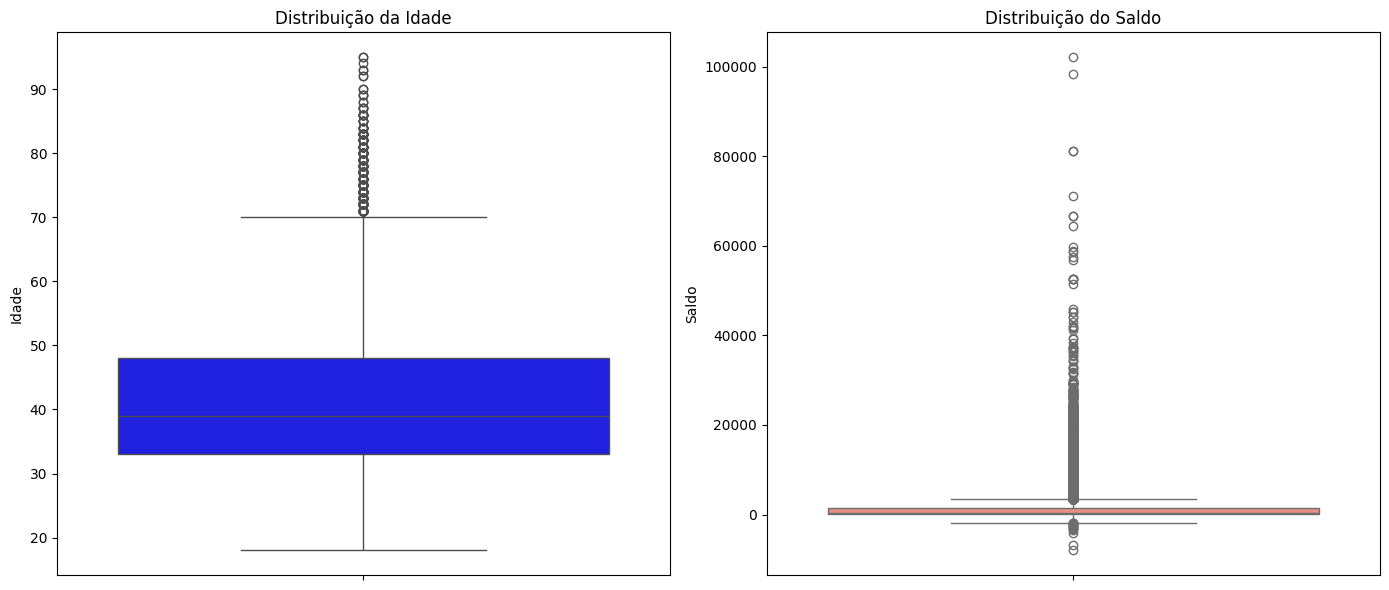

In [0]:
# 1. Converte apenas as colunas necessárias para Pandas (evita sobrecarregar a memória)
df_plot = df.select("age", "balance").toPandas()

#Configura a área de desenho para dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize = (14,6))

#Box Plot para a variável age
sns.boxplot(y=df_plot.age, ax=axes[0], color = "blue")
axes[0].set_title('Distribuição da Idade')
axes[0].set_ylabel("Idade")

#Box Plot para a variável balance
sns.boxplot(y=df_plot.balance, ax=axes[1], color = "salmon")
axes[1].set_title('Distribuição do Saldo')
axes[1].set_ylabel("Saldo")

# Ajusta o espaçamento e mostra os gráficos
plt.tight_layout()
plt.show()

In [0]:
# Análise da resposta do cliente (y).
total = df.count()

df.groupBy('y').agg(F.count("*").alias('resposta_cliente'), F.round(F.count('*')/total*100, 2).alias('percentual')).display()

y,resposta_cliente,percentual
yes,5289,11.7
no,39922,88.3


In [0]:
# Análise da variável education (escolaridade). 
total = df.count()

df.groupBy('education').agg(F.count("*").alias('escolaridade'), F.round(F.count('*')/total*100, 2).alias('percentual')).display()

education,escolaridade,percentual
tertiary,13301,29.42
secondary,23202,51.32
primary,6851,15.15
unknown,1857,4.11


In [0]:
# Análise da variável housing (empréstimo imobiliário)
total = df.count()

df.groupBy('housing').agg(F.count("*").alias('emprestimo_imobiliario'), F.round(F.count('*')/total*100, 2).alias('percentual')).display()

housing,emprestimo_imobiliario,percentual
yes,25130,55.58
no,20081,44.42


In [0]:
#Análise da variável marital (estado civil). 
total = df.count()

df.groupBy('marital').agg(F.count("*").alias('estado_civil'), F.round(F.count('*')/total*100, 2).alias('percentual')).display()

marital,estado_civil,percentual
single,12790,28.29
married,27214,60.19
divorced,5207,11.52


In [0]:
#Análise da variável default (Indicação de inadimplência)
total = df.count()

df.groupBy('default').agg(F.count("*").alias('inadimplência'), F.round(F.count('*')/total*100, 2).alias('percentual')).display()

default,inadimplência,percentual
yes,815,1.8
no,44396,98.2


In [0]:
#Distribuição de Clientes por Profissão
#O objetivo é identificar o principal segmento do banco.

total = df.count()

df.groupBy("job").agg(F.count("*").alias("total_clientes"),
                      F.round((F.count("*")*100/total), 2).alias("percentual")).orderBy("total_clientes", ascending=False).display()



job,total_clientes,percentual
blue-collar,9732,21.53
management,9458,20.92
technician,7597,16.8
admin.,5171,11.44
services,4154,9.19
retired,2264,5.01
self-employed,1579,3.49
entrepreneur,1487,3.29
unemployed,1303,2.88
housemaid,1240,2.74


In [0]:
#Análise de Inadimplência e Empréstimos (default, housing, loan)
#O objetivo é identificar se existe alguma relação entre a inadimplência e o empréstimo.

total = df.count()
df.groupBy("default", "housing", "loan").agg(F.count("*").alias("total_clientes"), F.round((F.count("*")*100/total), 2).alias("percentual")).orderBy("total_clientes", ascending=False).display()


default,housing,loan,total_clientes,percentual
no,yes,no,20461,45.26
no,no,no,16992,37.58
no,yes,yes,4234,9.36
no,no,yes,2709,5.99
yes,yes,no,302,0.67
yes,no,no,212,0.47
yes,no,yes,168,0.37
yes,yes,yes,133,0.29


In [0]:
# Análise de inadimplência dos clientes.
df.groupBy("default").count().display()

default,count
yes,815
no,44396


In [0]:
#Proporção de clientes que aceitaram e recusaram a oferta. 

total = df.count()
df.groupBy("y").agg(F.count("*").alias("total_clientes"), F.round((F.count("*"))*100/total, 2).alias("percentual")).display()

y,total_clientes,percentual
yes,5289,11.7
no,39922,88.3


In [0]:
#Verificar a qualidade dos dados 
# Conferir dimensões e tipos
print(pdf.shape)
pdf.info()

# Verificar valores ausentes
print(pdf.isnull().sum().sort_values(ascending=False))

# Verificar registros duplicados
print(f"Duplicados: {pdf.duplicated().sum()}")

# Conferir categorias e valores únicos
for coluna in pdf.select_dtypes(include=['object', 'category']).columns:
    print(f"\n{coluna}")
    print(pdf[coluna].value_counts(dropna=False))


(45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
age          0
day          0
poutcome     0
previous     0
pdays        0
campaign    

#Etapa 3. Seleção e tratamento das variáveis para o modelo. 

In [0]:
#Variaveis excluidas do modelo inicial

colunas_excluir = ['duration', 'campaign', 'contract', 'month', 'day', 'pdays', 'poutcome']

# base para a modelagem
colunas_modelo = [
    c for c in df.columns
    if c not in colunas_excluir 
]

X = df.select(colunas_modelo)


#X.display()


In [0]:
# Aplicar One-Hot Encoding para variáveis categóricas

colunas_categoricas = [
    "job",
    "marital",
    "education",
    "contact"
]

# Etapa 1: converter categorias em índices numéricos
indexadores = [
    StringIndexer(
        inputCol=coluna,
        outputCol=f"{coluna}_index",
        handleInvalid="keep"
    )
    for coluna in colunas_categoricas
]

# Etapa 2: converter índices em vetores One-Hot
codificadores = [
    OneHotEncoder(
        inputCol=f"{coluna}_index",
        outputCol=f"{coluna}_ohe",
        dropLast=False,
        handleInvalid="keep"
    )
    for coluna in colunas_categoricas
]

# Criar e ajustar o pipeline
pipeline = Pipeline(stages=indexadores + codificadores)

modelo_pipeline = pipeline.fit(df)

# Aplicar as transformações
df_encoded = modelo_pipeline.transform(df)

df_encoded.select(
    "job", "job_index", "job_ohe",
    "marital", "marital_index", "marital_ohe",
    "education", "education_index", "education_ohe",
    "contact", "contact_index", "contact_ohe"
).show(truncate=False)



+------------+---------+---------------+--------+-------------+-------------+---------+---------------+-------------+-------+-------------+-------------+
|job         |job_index|job_ohe        |marital |marital_index|marital_ohe  |education|education_index|education_ohe|contact|contact_index|contact_ohe  |
+------------+---------+---------------+--------+-------------+-------------+---------+---------------+-------------+-------+-------------+-------------+
|management  |1.0      |(14,[1],[1.0]) |married |0.0          |(5,[0],[1.0])|tertiary |1.0            |(6,[1],[1.0])|unknown|1.0          |(5,[1],[1.0])|
|technician  |2.0      |(14,[2],[1.0]) |single  |1.0          |(5,[1],[1.0])|secondary|0.0            |(6,[0],[1.0])|unknown|1.0          |(5,[1],[1.0])|
|entrepreneur|7.0      |(14,[7],[1.0]) |married |0.0          |(5,[0],[1.0])|secondary|0.0            |(6,[0],[1.0])|unknown|1.0          |(5,[1],[1.0])|
|blue-collar |0.0      |(14,[0],[1.0]) |married |0.0          |(5,[0],[1.0])

In [0]:
#Converter as variáveis binárias

colunas_binarias = ["default", "housing", "loan", "y"]

df_binario = df_encoded

for coluna in colunas_binarias:
    df_binario = df_binario.withColumn(
        coluna, F.when(F.lower(F.trim(F.col(coluna)))=='yes', 1)
                 .when(F.lower(F.trim(F.col(coluna)))=='no', 0)
                 .otherwise(None)
                 .cast('integer')      
    )

#df_binario.display()

#Etapa 4. Modelagem 

Vamos iniciar nossa modelagem com uma Regressão Logística, modelo de classificação que estima a possibilidade de um cliente aceitar a oferta. 

Variáveis numéricas e binárias: age, balance, default, housing, loan, previous.
Vetores One-Hot: job_ohe, marital_ohe, education_ohe, contact_ohe.
Alvo: y.

In [0]:
# Variáveis numéricas e binárias
colunas_numericas = [
    "age",
    "balance",
    "default",
    "housing",
    "loan",
    "previous"
]

# Colunas que contêm os vetores do One-Hot Encoding
colunas_ohe = [
    "job_ohe",
    "marital_ohe",
    "education_ohe",
    "contact_ohe"
]

# Todas as variáveis preditoras
colunas_features = colunas_numericas + colunas_ohe

# Separar as colunas que serão utilizadas
df_modelagem = df_binario.select(
    *colunas_features,
    "y"
).na.drop()

# Reunir tudo em um único vetor
assembler = VectorAssembler(
    inputCols=colunas_features,
    outputCol="features"
)

df_final = assembler.transform(df_modelagem)

# Conferir o resultado
df_final.select("features", "y").show(
    5,
    truncate=False
)


+-------------------------------------------------------------+---+
|features                                                     |y  |
+-------------------------------------------------------------+---+
|(36,[0,1,3,7,20,26,32],[58.0,2143.0,1.0,1.0,1.0,1.0,1.0])    |0  |
|(36,[0,1,3,8,21,25,32],[44.0,29.0,1.0,1.0,1.0,1.0,1.0])      |0  |
|(36,[0,1,3,4,13,20,25,32],[33.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0])|0  |
|(36,[0,1,3,6,20,28,32],[47.0,1506.0,1.0,1.0,1.0,1.0,1.0])    |0  |
|(36,[0,1,17,21,28,32],[33.0,1.0,1.0,1.0,1.0,1.0])            |0  |
+-------------------------------------------------------------+---+
only showing top 5 rows


In [0]:
#Dividir os dados em treino e teste
#Usaremos aproximadamente 80% para treinamento e 20% para teste.

treino, teste = df_final.randomSplit(
    [0.8, 0.2],
    seed=42
)

print(f"Registros para treino: {treino.count()}")
print(f"Registros para teste: {teste.count()}")

Registros para treino: 36371
Registros para teste: 8840


In [0]:
#Treinar a Regressão Logística
#Saída: Considere o vetor [0.6, 0.4] como saída do modelo. Isso significa que, o modelo estimou 60% de probabilidade para a classe 0 e 40% para a classe 1. 

reg_logistica = LogisticRegression(
    featuresCol="features",
    labelCol="y",
    predictionCol="prediction",
    probabilityCol="probability",
    maxIter=100
)

modelo = reg_logistica.fit(treino)

# Fazer previsões sobre os dados de teste
previsoes = modelo.transform(teste)

previsoes.select(
    "y",
    "prediction",
    "probability"
).show(10, truncate=False)



+---+----------+-----------------------------------------+
|y  |prediction|probability                              |
+---+----------+-----------------------------------------+
|0  |0.0       |[0.9339099428338586,0.06609005716614136] |
|0  |0.0       |[0.9153892209473057,0.08461077905269432] |
|0  |0.0       |[0.9820443849005653,0.017955615099434663]|
|0  |0.0       |[0.9335486968442773,0.06645130315572267] |
|0  |0.0       |[0.9667202877924611,0.03327971220753889] |
|0  |0.0       |[0.9720679532882751,0.02793204671172489] |
|0  |0.0       |[0.9857857923447867,0.014214207655213307]|
|0  |0.0       |[0.933216016820195,0.06678398317980505]  |
|0  |0.0       |[0.9680717265313887,0.03192827346861127] |
|0  |0.0       |[0.9296331773437047,0.07036682265629535] |
+---+----------+-----------------------------------------+
only showing top 10 rows


In [0]:
def avaliar_modelo(modelo, teste, nome):
    # Gerar previsões no conjunto de teste
    previsoes = modelo.transform(teste)

    # AUC-ROC
    avaliador_roc = BinaryClassificationEvaluator(
        labelCol="y",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )
    auc_roc = avaliador_roc.evaluate(previsoes)

    # AUC-PR
    avaliador_pr = BinaryClassificationEvaluator(
        labelCol="y",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR"
    )
    auc_pr = avaliador_pr.evaluate(previsoes)

    # Matriz de confusão
    resultado = previsoes.agg(
        F.sum(F.when(
            (F.col("y") == 1) & (F.col("prediction") == 1), 1
        ).otherwise(0)).alias("TP"),

        F.sum(F.when(
            (F.col("y") == 0) & (F.col("prediction") == 0), 1
        ).otherwise(0)).alias("TN"),

        F.sum(F.when(
            (F.col("y") == 0) & (F.col("prediction") == 1), 1
        ).otherwise(0)).alias("FP"),

        F.sum(F.when(
            (F.col("y") == 1) & (F.col("prediction") == 0), 1
        ).otherwise(0)).alias("FN")
    ).first()

    tp, tn, fp, fn = (
        resultado["TP"], resultado["TN"],
        resultado["FP"], resultado["FN"]
    )

    precisao = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    acuracia = (tp + tn) / (tp + tn + fp + fn)

    print(f"\n===== {nome} =====")
    print(f"AUC-ROC:  {auc_roc:.4f}")
    print(f"AUC-PR:   {auc_pr:.4f}")
    print(f"Acurácia: {acuracia:.4f}")
    print(f"Precisão: {precisao:.4f}")
    print(f"Recall:   {recall:.4f}")

    print("\nMatriz de confusão:")
    print("                 Previsto 0    Previsto 1")
    print(f"Real 0 (TN/FP)   {tn:10d}    {fp:10d}")
    print(f"Real 1 (FN/TP)   {fn:10d}    {tp:10d}")

    return previsoes, {
        "modelo": nome,
        "auc_roc": auc_roc,
        "auc_pr": auc_pr,
        "acuracia": acuracia,
        "precisao": precisao,
        "recall": recall
    }

previsoes_lr, metricas_lr = avaliar_modelo(
    modelo, teste, "Regressão Logística"
)



===== Regressão Logística =====
AUC-ROC:  0.7097
AUC-PR:   0.2591
Acurácia: 0.8787
Precisão: 0.2778
Recall:   0.0047

Matriz de confusão:
                 Previsto 0    Previsto 1
Real 0 (TN/FP)         7763            13
Real 1 (FN/TP)         1059             5


Análise: 
1. Quanto a matriz de confusão: 
- 7.763 verdadeiros negativos (TN): o modelo identificou corretamente clientes que não contrataram.
- 13 falsos positivos (FP): o modelo indicou propensão à contratação, mas esses clientes não contrataram.
- 1.059 falsos negativos (FN): clientes que contrataram, mas o modelo não identificou como positivos.
- 5 verdadeiros positivos (TP): apenas seis clientes que contrataram foram identificados corretamente.
Ou seja, havia 1.064 clientes que efetivamente contrataram, mas o modelo identificou apenas seis deles.
Esse é o ponto mais importante do diagnóstico.


In [0]:
#Vamos fazer uma análise do vetor probabilidade
previsoes_lr = modelo.transform(teste)

previsoes_lr.select(
    "y",
    "prediction",
    "probability"
).show(10, truncate=False)

+---+----------+-----------------------------------------+
|y  |prediction|probability                              |
+---+----------+-----------------------------------------+
|0  |0.0       |[0.9339099428338586,0.06609005716614136] |
|0  |0.0       |[0.9153892209473057,0.08461077905269432] |
|0  |0.0       |[0.9820443849005653,0.017955615099434663]|
|0  |0.0       |[0.9335486968442773,0.06645130315572267] |
|0  |0.0       |[0.9667202877924611,0.03327971220753889] |
|0  |0.0       |[0.9720679532882751,0.02793204671172489] |
|0  |0.0       |[0.9857857923447867,0.014214207655213307]|
|0  |0.0       |[0.933216016820195,0.06678398317980505]  |
|0  |0.0       |[0.9680717265313887,0.03192827346861127] |
|0  |0.0       |[0.9296331773437047,0.07036682265629535] |
+---+----------+-----------------------------------------+
only showing top 10 rows


In [0]:
previsoes_lr.groupBy("prediction").count().show()

+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 8822|
|       1.0|   18|
+----------+-----+



In [0]:
teste.groupBy("y").count().show()

+---+-----+
|  y|count|
+---+-----+
|  1| 1064|
|  0| 7776|
+---+-----+



In [0]:
previsoes_lr.agg(
    F.sum(
        F.when(
            (F.col("y") == 1) & (F.col("prediction") == 1),
            1
        ).otherwise(0)
    ).alias("contratantes_identificados")
).show()

+--------------------------+
|contratantes_identificados|
+--------------------------+
|                         5|
+--------------------------+



In [0]:
previsoes_lr = previsoes_lr.withColumn(
    "prob_array",
    vector_to_array("probability", "float32")
)

previsoes_lr.select("prob_array").show(5, truncate=False)

+-------------------------+
|prob_array               |
+-------------------------+
|[0.93390995, 0.066090055]|
|[0.91538924, 0.08461078] |
|[0.9820444, 0.017955614] |
|[0.9335487, 0.0664513]   |
|[0.9667203, 0.033279713] |
+-------------------------+
only showing top 5 rows


In [0]:
previsoes_lr = previsoes_lr.withColumn(
    "prob_contratacao",
    F.col("prob_array")[1]
)

previsoes_lr.select(
    "y",
    "prediction",
    "prob_contratacao"
).show(10, truncate=False)

+---+----------+----------------+
|y  |prediction|prob_contratacao|
+---+----------+----------------+
|0  |0.0       |0.066090055     |
|0  |0.0       |0.08461078      |
|0  |0.0       |0.017955614     |
|0  |0.0       |0.0664513       |
|0  |0.0       |0.033279713     |
|0  |0.0       |0.027932046     |
|0  |0.0       |0.014214207     |
|0  |0.0       |0.06678398      |
|0  |0.0       |0.031928275     |
|0  |0.0       |0.07036682      |
+---+----------+----------------+
only showing top 10 rows


In [0]:
#Vamos entender quais probabilidades o modelo está atribuindo aos clientes. 
previsoes_lr.select(
    F.min("prob_contratacao").alias("prob_minima"),
    F.max("prob_contratacao").alias("prob_maxima"),
    F.avg("prob_contratacao").alias("prob_media")
).show()

+-----------+-----------+-------------------+
|prob_minima|prob_maxima|         prob_media|
+-----------+-----------+-------------------+
|0.007534403| 0.76804477|0.11703968853231443|
+-----------+-----------+-------------------+



A média de 11,70% é próxima da proporção real de contratações no conjunto de teste, que é de 11,65%. Isso é interessante, mas não garante, por si só, que as probabilidades estejam bem calibradas.
Também é importante lembrar que, embora algumas probabilidades sejam altas, o modelo só classifica um cliente como contratante quando a probabilidade ultrapassa o limiar padrão de 50%.
Vamos investigar um limiar menor. Em vez de mudar o modelo, vamos apenas contar quantos clientes seriam selecionados se usássemos um limiar de 20%.

In [0]:
previsoes_lr.filter(
    F.col("prob_contratacao") >= 0.20
).count()

1255

In [0]:
# Criar previsões com limiar customizado de 20% (em vez do padrão de 50%)
previsoes_limiar_20 = previsoes_lr.withColumn(
    "prediction",
    F.when(F.col("prob_contratacao") >= 0.20, 1).otherwise(0)
)

# Avaliar usando a função avaliar_modelo
# Nota: avaliar_modelo re-executa modelo.transform(teste) internamente,
# sobrescrevendo a coluna prediction. Por isso, replicamos a lógica
# da função manualmente para usar o limiar de 20%.

resultado = previsoes_limiar_20.agg(
    F.sum(F.when(
        (F.col("y") == 1) & (F.col("prediction") == 1), 1
    ).otherwise(0)).alias("TP"),

    F.sum(F.when(
        (F.col("y") == 0) & (F.col("prediction") == 0), 1
    ).otherwise(0)).alias("TN"),

    F.sum(F.when(
        (F.col("y") == 0) & (F.col("prediction") == 1), 1
    ).otherwise(0)).alias("FP"),

    F.sum(F.when(
        (F.col("y") == 1) & (F.col("prediction") == 0), 1
    ).otherwise(0)).alias("FN")
).first()

tp, tn, fp, fn = resultado["TP"], resultado["TN"], resultado["FP"], resultado["FN"]

precisao = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
acuracia = (tp + tn) / (tp + tn + fp + fn)

print("\n===== Regressão Logística (limiar 20%) =====")
print(f"Acurácia: {acuracia:.4f}")
print(f"Precisão: {precisao:.4f}")
print(f"Recall:   {recall:.4f}")

print("\nMatriz de confusão:")
print("                 Previsto 0    Previsto 1")
print(f"Real 0 (TN/FP)   {tn:10d}    {fp:10d}")
print(f"Real 1 (FN/TP)   {fn:10d}    {tp:10d}")


===== Regressão Logística (limiar 20%) =====
Acurácia: 0.8241
Precisão: 0.3044
Recall:   0.3590

Matriz de confusão:
                 Previsto 0    Previsto 1
Real 0 (TN/FP)         6903           873
Real 1 (FN/TP)          682           382


Nesse caso, o modelo identificou corretamente 382 das 1255 contratações no conjunto de teste.

Duas métricas importantes

Precisão: 30.44% — entre os clientes selecionados, aproximadamente 30% contrataram.
Recall: 35.90% — dentre os 1.255 registros classificados como positivos, 382 apresentaram contratação. Compare com o limiar de 50%: ele identificou apenas 5 contratantes. Ao reduzir o limiar para 20%, identificamos 382. Isso mostra como o limiar muda o comportamento do modelo. Atenção: o limiar de 20% ainda não é necessariamente o melhor. Precisamos considerar o custo da campanha, o valor de uma contratação e a quantidade de clientes que o banco consegue abordar.

Vamos comparar com o limiar de 10% Agora vamos fazer um experimento simples, sem treinar o modelo novamente: contar quantos clientes seriam selecionados com probabilidade de contratação igual ou superior a 10%.

In [0]:
previsoes_lr.filter(
    F.col("prob_contratacao") >= 0.20
).groupBy("y").count().show()

+---+-----+
|  y|count|
+---+-----+
|  1|  382|
|  0|  873|
+---+-----+



In [0]:
selecionados_20 = previsoes_lr.filter(
    F.col("prob_contratacao") >= 0.20
)

selecionados_20.agg(
    F.sum(
        F.when(F.col("y") == 1, 1).otherwise(0)
    ).alias("contratantes_identificados"),
    F.count("*").alias("total_selecionados")
).show()

+--------------------------+------------------+
|contratantes_identificados|total_selecionados|
+--------------------------+------------------+
|                       382|              1255|
+--------------------------+------------------+



In [0]:
previsoes_lr.filter(
    F.col("prob_contratacao") >= 0.10
).groupBy("y").count().show()

+---+-----+
|  y|count|
+---+-----+
|  1|  810|
|  0| 3666|
+---+-----+



In [0]:
selecionados_10 = previsoes_lr.filter(
    F.col("prob_contratacao") >= 0.10
)

selecionados_10.agg(
    F.sum(
        F.when(F.col("y") == 1, 1).otherwise(0)
    ).alias("contratantes_identificados"),
    F.count("*").alias("total_selecionados")
).show()

+--------------------------+------------------+
|contratantes_identificados|total_selecionados|
+--------------------------+------------------+
|                       810|              4476|
+--------------------------+------------------+



In [0]:
def avaliar_limiar(previsoes, limiar):
    selecionados = previsoes.filter(
        F.col("prob_contratacao") >= limiar
    )

    total_selecionados = selecionados.count()

    contratantes_identificados = selecionados.filter(
        F.col("y") == 1
    ).count()

    total_contratantes = previsoes.filter(
        F.col("y") == 1
    ).count()

    precisao = (
        contratantes_identificados / total_selecionados
        if total_selecionados > 0 else 0
    )

    recall = (
        contratantes_identificados / total_contratantes
        if total_contratantes > 0 else 0
    )

    return {
        "limiar": limiar,
        "clientes_selecionados": total_selecionados,
        "contratantes_identificados": contratantes_identificados,
        "precisao": precisao,
        "recall": recall
    }

In [0]:
resultado_10 = avaliar_limiar(previsoes_lr, 0.10)
resultado_20 = avaliar_limiar(previsoes_lr, 0.20)

print("Limiar de 10%:", resultado_10)
print("Limiar de 20%:", resultado_20)

Limiar de 10%: {'limiar': 0.1, 'clientes_selecionados': 4476, 'contratantes_identificados': 810, 'precisao': 0.18096514745308312, 'recall': 0.7612781954887218}
Limiar de 20%: {'limiar': 0.2, 'clientes_selecionados': 1255, 'contratantes_identificados': 382, 'precisao': 0.3043824701195219, 'recall': 0.35902255639097747}


In [0]:
limiares = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

resultados = []

for limiar in limiares:
    resultado = avaliar_limiar(previsoes_lr, limiar)
    resultados.append(resultado)

resultados

[{'limiar': 0.05,
  'clientes_selecionados': 6713,
  'contratantes_identificados': 969,
  'precisao': 0.14434678981081484,
  'recall': 0.9107142857142857},
 {'limiar': 0.1,
  'clientes_selecionados': 4476,
  'contratantes_identificados': 810,
  'precisao': 0.18096514745308312,
  'recall': 0.7612781954887218},
 {'limiar': 0.15,
  'clientes_selecionados': 2556,
  'contratantes_identificados': 596,
  'precisao': 0.23317683881064163,
  'recall': 0.5601503759398496},
 {'limiar': 0.2,
  'clientes_selecionados': 1255,
  'contratantes_identificados': 382,
  'precisao': 0.3043824701195219,
  'recall': 0.35902255639097747},
 {'limiar': 0.25,
  'clientes_selecionados': 568,
  'contratantes_identificados': 214,
  'precisao': 0.3767605633802817,
  'recall': 0.20112781954887218},
 {'limiar': 0.3,
  'clientes_selecionados': 282,
  'contratantes_identificados': 112,
  'precisao': 0.3971631205673759,
  'recall': 0.10526315789473684}]

In [0]:
#Consolidando os resultados com os diferentes limiares em um DataFrame
df_resultados = pd.DataFrame(resultados)

df_resultados

,limiar,clientes_selecionados,contratantes_identificados,precisao,recall
0,0.05,6713,969,0.144347,0.910714
1,0.10,4476,810,0.180965,0.761278
2,0.15,2556,596,0.233177,0.560150
3,0.20,1255,382,0.304382,0.359023
4,0.25,568,214,0.376761,0.201128
5,0.30,282,112,0.397163,0.105263


In [0]:
df_resultados_formatado = df_resultados.copy()

df_resultados_formatado["precisao"] = (
    df_resultados_formatado["precisao"].map("{:.2%}".format)
)

df_resultados_formatado["recall"] = (
    df_resultados_formatado["recall"].map("{:.2%}".format)
)

df_resultados_formatado

,limiar,clientes_selecionados,contratantes_identificados,precisao,recall
0,0.05,6713,969,14.43%,91.07%
1,0.10,4476,810,18.10%,76.13%
2,0.15,2556,596,23.32%,56.02%
3,0.20,1255,382,30.44%,35.90%
4,0.25,568,214,37.68%,20.11%
5,0.30,282,112,39.72%,10.53%


In [0]:
avaliador_pr = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

auc_pr = avaliador_pr.evaluate(previsoes_lr)

#print(f"AUC-PR: {auc_pr:.4f}")

In [0]:
avaliador_roc = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

auc_roc = avaliador_roc.evaluate(previsoes_lr)

print(f"AUC-ROC: {auc_roc:.4f}")
print(f"AUC-PR:  {auc_pr:.4f}")

AUC-ROC: 0.7096
AUC-PR:  0.2591


AUC-ROC = 0,7096. 
O modelo apresenta capacidade de distinguir clientes que contrataram daqueles que não contrataram melhor do que uma classificação aleatória, embora ainda haja espaço para melhorar.
AUC-PR = 0,2591. 
Essa métrica resume a relação entre precisão e recall ao longo dos limiares. É especialmente útil no seu problema, pois os clientes que contrataram representam apenas cerca de 11,65% do conjunto de teste.

Passamos agora a analisar o modelo de classificação DecisionTreeClassifier

In [0]:
#featuresCol="features": usa as variáveis explicativas que você já preparou.
#labelCol="y": indica a variável que queremos prever.
#maxDepth=5: limita a profundidade da árvore para controlar sua complexidade.
#seed=42: ajuda a manter a reprodutibilidade quando o algoritmo utiliza aleatoriedade.

arvore = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="y",
    predictionCol="prediction",
    probabilityCol="probability",
    maxDepth=5,
    seed=42
)

In [0]:
modelo_arvore = arvore.fit(treino)
previsoes_arvore = modelo_arvore.transform(teste)

previsoes_arvore.select(
    "y",
    "prediction"
).show(10)

+---+----------+
|  y|prediction|
+---+----------+
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
|  0|       0.0|
+---+----------+
only showing top 10 rows


In [0]:
previsoes_arvore.groupBy("prediction").count().show()

+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 8830|
|       1.0|   10|
+----------+-----+



In [0]:
avaliador_roc = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

auc_roc_arvore = avaliador_roc.evaluate(previsoes_arvore)

avaliador_pr = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

auc_pr_arvore = avaliador_pr.evaluate(previsoes_arvore)

print(f"AUC-ROC da árvore: {auc_roc_arvore:.4f}")
print(f"AUC-PR da árvore: {auc_pr_arvore:.4f}")

AUC-ROC da árvore: 0.5265
AUC-PR da árvore: 0.1236


In [0]:
previsoes_arvore.select(
    "y",
    "probability",
    "rawPrediction"
).show(10, truncate=False)

+---+----------------------------------------+---------------+
|y  |probability                             |rawPrediction  |
+---+----------------------------------------+---------------+
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
|0  |[0.9614135625596943,0.03858643744030563]|[10066.0,404.0]|
+---+----------------------------------------+---------------+
only showing top 10 rows


In [0]:
previsoes_arvore = previsoes_arvore.withColumn(
    "prob_array",
    vector_to_array("probability", "float32")
)

previsoes_arvore = previsoes_arvore.withColumn(
    "prob_contratacao",
    F.col("prob_array")[1]
)

previsoes_arvore.select(
    "y",
    "prob_contratacao"
).show(10, truncate=False)

+---+----------------+
|y  |prob_contratacao|
+---+----------------+
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
|0  |0.038586438     |
+---+----------------+
only showing top 10 rows


In [0]:
previsoes_arvore.select(
    F.min("prob_contratacao").alias("prob_minima"),
    F.max("prob_contratacao").alias("prob_maxima"),
    F.avg("prob_contratacao").alias("prob_media")
).show()

+-----------+-----------+-------------------+
|prob_minima|prob_maxima|         prob_media|
+-----------+-----------+-------------------+
|        0.0|  0.5714286|0.11638219320548202|
+-----------+-----------+-------------------+



In [0]:
#Quantas probabilidades diferentes a árvore gerou: 

previsoes_arvore.groupBy(
    "prob_contratacao"
).count().orderBy(
    F.desc("count")
).show(20, truncate=False)

+----------------+-----+
|prob_contratacao|count|
+----------------+-----+
|0.10922449      |4578 |
|0.038586438     |2480 |
|0.123908825     |951  |
|0.4283217       |554  |
|0.28857142      |166  |
|0.14009662      |60   |
|0.41958043      |38   |
|0.5714286       |10   |
|0.0             |3    |
+----------------+-----+



In [0]:
previsoes_arvore = previsoes_arvore.withColumn(
    "prob_contratacao",
    F.col("prob_contratacao").cast("double")
)

avaliador_roc_prob = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="prob_contratacao",
    metricName="areaUnderROC"
)

auc_roc_prob_arvore = avaliador_roc_prob.evaluate(
    previsoes_arvore
)

print(f"AUC-ROC usando probabilidade: {auc_roc_prob_arvore:.4f}")

AUC-ROC usando probabilidade: 0.6722


In [0]:
avaliador_pr_prob = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="prob_contratacao",
    metricName="areaUnderPR"
)

auc_pr_prob_arvore = avaliador_pr_prob.evaluate(
    previsoes_arvore
)

print(f"AUC-PR usando probabilidade: {auc_pr_prob_arvore:.4f}")

AUC-PR usando probabilidade: 0.2608


In [0]:
#Avaliar a árvore com limiares diferentes

limiares = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

resultados_arvore = [
    avaliar_limiar(previsoes_arvore, limiar)
    for limiar in limiares
]

df_resultados_arvore = pd.DataFrame(resultados_arvore)

df_resultados_arvore

,limiar,clientes_selecionados,contratantes_identificados,precisao,recall
0,0.05,6357,950,0.149442,0.892857
1,0.10,6357,950,0.149442,0.892857
2,0.15,768,299,0.389323,0.281015
3,0.20,768,299,0.389323,0.281015
4,0.25,768,299,0.389323,0.281015
5,0.30,602,248,0.411960,0.233083


In [0]:
#Análise dos dois modelos: 

limiares = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

resultados_lr = [
    avaliar_limiar(previsoes_lr, limiar)
    for limiar in limiares
]

df_resultados_lr = pd.DataFrame(resultados_lr)

df_resultados_lr

,limiar,clientes_selecionados,contratantes_identificados,precisao,recall
0,0.05,6713,969,0.144347,0.910714
1,0.10,4476,810,0.180965,0.761278
2,0.15,2556,596,0.233177,0.560150
3,0.20,1255,382,0.304382,0.359023
4,0.25,568,214,0.376761,0.201128
5,0.30,282,112,0.397163,0.105263


In [0]:
print("Regressão logística:")
previsoes_lr.select(
    "y", "prob_contratacao"
).printSchema()

print("Árvore de decisão:")
previsoes_arvore.select(
    "y", "prob_contratacao"
).printSchema()

Regressão logística:
root
 |-- y: integer (nullable = true)
 |-- prob_contratacao: float (nullable = true)

Árvore de decisão:
root
 |-- y: integer (nullable = true)
 |-- prob_contratacao: double (nullable = true)



In [0]:
# Selecionar os 700 clientes com maior probabilidade
top700_lr = previsoes_lr.orderBy(
    F.desc("prob_contratacao")
).limit(700)

top700_arvore = previsoes_arvore.orderBy(
    F.desc("prob_contratacao")
).limit(700)

# Avaliar os resultados de cada modelo
print("Regressão logística")
top700_lr.agg(
    F.count("*").alias("clientes_selecionados"),
    F.sum("y").alias("contratantes_identificados"),
    F.avg("y").alias("precisao")
).show()

print("Árvore de decisão")
top700_arvore.agg(
    F.count("*").alias("clientes_selecionados"),
    F.sum("y").alias("contratantes_identificados"),
    F.avg("y").alias("precisao")
).show()

Regressão logística
+---------------------+--------------------------+------------------+
|clientes_selecionados|contratantes_identificados|          precisao|
+---------------------+--------------------------+------------------+
|                  700|                       249|0.3557142857142857|
+---------------------+--------------------------+------------------+

Árvore de decisão
+---------------------+--------------------------+-------------------+
|clientes_selecionados|contratantes_identificados|           precisao|
+---------------------+--------------------------+-------------------+
|                  700|                       272|0.38857142857142857|
+---------------------+--------------------------+-------------------+



In [0]:
total_contratantes = previsoes_lr.filter(
    F.col("y") == 1
).count()

print(f"Total de contratantes no teste: {total_contratantes}")

recall_lr = 259 / total_contratantes
recall_arvore = 289 / total_contratantes

print(f"Recall da regressão logística: {recall_lr:.2%}")
print(f"Recall da árvore de decisão: {recall_arvore:.2%}")

Total de contratantes no teste: 1064
Recall da regressão logística: 24.34%
Recall da árvore de decisão: 27.16%


In [0]:
etapas = list(modelo_pipeline.stages)

print("Quantidade de etapas:", len(etapas))

for i in range(len(etapas)):
    etapa = etapas[i]
    print(i, type(etapa).__name__)

Quantidade de etapas: 8
0 StringIndexerModel
1 StringIndexerModel
2 StringIndexerModel
3 StringIndexerModel
4 OneHotEncoderModel
5 OneHotEncoderModel
6 OneHotEncoderModel
7 OneHotEncoderModel


In [0]:
for etapa in modelo_pipeline.stages:
    if type(etapa).__name__ == "OneHotEncoderModel":
        print(etapa.getOutputCol(), etapa.categorySizes)

job_ohe [13]
marital_ohe [4]
education_ohe [5]
contact_ohe [4]


In [0]:
importancias = modelo_arvore.featureImportances.toArray()

df_importancias = pd.DataFrame({
    "indice": range(len(importancias)),
    "importancia": importancias
}).sort_values("importancia", ascending=False)

df_importancias.head(15)

,indice,importancia
3,3,0.357593
5,5,0.325761
32,32,0.128152
0,0,0.122332
4,4,0.043391
22,22,0.007800
27,27,0.004733
31,31,0.004347
12,12,0.003905
1,1,0.001986


In [0]:
nomes_features = [
    "age", "balance", "default", "housing", "loan", "previous"
]

tamanhos_reais = {
    "job": 14,
    "marital": 5,
    "education": 6,
    "contact": 5
}

for etapa in etapas:
    if type(etapa).__name__ == "StringIndexerModel":
        coluna = etapa.getInputCol()
        categorias = list(etapa.labels)

        nomes_features.extend(
            [f"{coluna}_{categoria}" for categoria in categorias]
        )

        tamanho_atual = len(categorias) + 0
        tamanho_real = tamanhos_reais[coluna]

        for i in range(tamanho_real - tamanho_atual):
            nomes_features.append(
                f"{coluna}_posicao_extra_{i + 1}"
            )

print("Total de nomes:", len(nomes_features))

In [0]:
importancias = modelo_arvore.featureImportances.toArray()

df_importancias = pd.DataFrame({
    "indice": range(len(importancias)),
    "variavel": nomes_features,
    "importancia": importancias
})

df_importancias = df_importancias.sort_values(
    "importancia",
    ascending=False
)

df_importancias.head(15)

,indice,variavel,importancia
3,3,housing,0.357593
5,5,previous,0.325761
32,32,contact_unknown,0.128152
0,0,age,0.122332
4,4,loan,0.043391
22,22,marital_divorced,0.007800
27,27,education_primary,0.004733
31,31,contact_cellular,0.004347
12,12,job_self-employed,0.003905
1,1,balance,0.001986


In [0]:
df_com_id = df.withColumn(
    "id_registro",
    F.monotonically_increasing_id()
)

df_com_id.select("id_registro", "age", "job", "balance", "y").show(10)

+-----------+---+------------+-------+---+
|id_registro|age|         job|balance|  y|
+-----------+---+------------+-------+---+
|          0| 58|  management|   2143| no|
|          1| 44|  technician|     29| no|
|          2| 33|entrepreneur|      2| no|
|          3| 47| blue-collar|   1506| no|
|          4| 33|     unknown|      1| no|
+-----------+---+------------+-------+---+
only showing top 5 rows


In [0]:
# Fazer o estudo com 2000 pessoas da base de teste.

top_2000_lr = (
    previsoes_lr
    .orderBy(F.col("prob_contratacao").desc())
    .limit(2000)
)

print("Clientes selecionados:", top_2000_lr.count())

print(
    "Contratações identificadas:",
    top_2000_lr.filter(F.col("y") == 1).count()
)

Clientes selecionados: 2000
Contratações identificadas: 513


In [0]:
top_2000_arvore = (
    previsoes_arvore
    .orderBy(F.col("prob_contratacao").desc())
    .limit(2000)
)

print("Clientes selecionados:", top_2000_arvore.count())

print(
    "Contratações identificadas:",
    top_2000_arvore.filter(F.col("y") == 1).count()
)

Clientes selecionados: 2000
Contratações identificadas: 435


In [0]:
colunas_cliente = [
    "age",
    "job",
    "marital",
    "education",
    "balance",
    "housing",
    "loan",
    "contact",
    "y",
    "prob_contratacao"
]

top_2000_lr.select(
    *[c for c in colunas_cliente if c in top_2000_lr.columns]
).show(20, truncate=False)

+---+-------+-------+----+---+----------------+
|age|balance|housing|loan|y  |prob_contratacao|
+---+-------+-------+----+---+----------------+
|26 |725    |0      |0   |1  |0.76804477      |
|84 |81204  |0      |0   |1  |0.7271702       |
|28 |4987   |0      |0   |1  |0.67620647      |
|43 |497    |0      |0   |0  |0.6633707       |
|49 |196    |0      |0   |0  |0.65658194      |
|59 |98417  |0      |0   |0  |0.6521936       |
|60 |71188  |0      |0   |0  |0.6374489       |
|31 |988    |0      |0   |0  |0.5810599       |
|55 |719    |1      |0   |0  |0.57123494      |
|59 |64343  |0      |0   |0  |0.5504891       |
|74 |29080  |0      |0   |1  |0.5409478       |
|47 |-49    |1      |0   |0  |0.54023725      |
|39 |467    |1      |0   |0  |0.5326532       |
|29 |3054   |0      |0   |0  |0.5245138       |
|34 |2481   |0      |0   |0  |0.514869        |
|61 |52587  |0      |0   |1  |0.51412225      |
|55 |8044   |1      |0   |0  |0.5074662       |
|35 |667    |1      |0   |0  |0.5013017 

In [0]:
df_binario_id = (
    df_com_id
    .withColumn(
        "default",
        F.when(F.col("default") == "yes", 1).otherwise(0)
    )
    .withColumn(
        "housing",
        F.when(F.col("housing") == "yes", 1).otherwise(0)
    )
    .withColumn(
        "loan",
        F.when(F.col("loan") == "yes", 1).otherwise(0)
    )
    .withColumn(
        "y",
        F.when(F.col("y") == "yes", 1).otherwise(0)
    )
)

print(df_binario_id.columns)
df_binario_id.select("id_registro", "default", "housing", "loan", "y").show(5)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'id_registro']
+-----------+-------+-------+----+---+
|id_registro|default|housing|loan|  y|
+-----------+-------+-------+----+---+
|          0|      0|      1|   0|  0|
|          1|      0|      1|   0|  0|
|          2|      0|      1|   1|  0|
|          3|      0|      1|   0|  0|
|          4|      0|      0|   0|  0|
+-----------+-------+-------+----+---+
only showing top 5 rows


In [0]:
# Aplicar os indexadores e encoders já ajustados
df_codificado_id = modelo_pipeline.transform(df_binario_id)

# Manter as mesmas características do modelo original,
# além do identificador técnico
df_modelagem_id = df_codificado_id.select(
    "id_registro",
    *colunas_features,
    "y"
).na.drop()

# Montar o vetor de características
df_final_id = assembler.transform(df_modelagem_id)

print("Total de registros:", df_final_id.count())
print("Dimensão do vetor:", df_final_id.select("features").first()["features"].size)

df_final_id.select("id_registro", "y", "features").show(5, truncate=False)

Total de registros: 45211
Dimensão do vetor: 36
+-----------+---+-------------------------------------------------------------+
|id_registro|y  |features                                                     |
+-----------+---+-------------------------------------------------------------+
|0          |0  |(36,[0,1,3,7,20,26,32],[58.0,2143.0,1.0,1.0,1.0,1.0,1.0])    |
|1          |0  |(36,[0,1,3,8,21,25,32],[44.0,29.0,1.0,1.0,1.0,1.0,1.0])      |
|2          |0  |(36,[0,1,3,4,13,20,25,32],[33.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|3          |0  |(36,[0,1,3,6,20,28,32],[47.0,1506.0,1.0,1.0,1.0,1.0,1.0])    |
|4          |0  |(36,[0,1,17,21,28,32],[33.0,1.0,1.0,1.0,1.0,1.0])            |
+-----------+---+-------------------------------------------------------------+
only showing top 5 rows


In [0]:
# Separar os dados: 80% para treino e 20% para teste
treino_id, teste_id = df_final_id.randomSplit([0.8, 0.2], seed=42)

print("Registros para treino:", treino_id.count())
print("Registros para teste:", teste_id.count())

# Treinar regressão logística
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier

reg_logistica_id = LogisticRegression(
    featuresCol="features",
    labelCol="y",
    predictionCol="prediction",
    probabilityCol="probability",
    maxIter=100
)

modelo_lr_id = reg_logistica_id.fit(treino_id)

# Treinar árvore de decisão
arvore_id = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="y",
    predictionCol="prediction",
    probabilityCol="probability",
    maxDepth=5,
    seed=42
)

modelo_arvore_id = arvore_id.fit(treino_id)

print("Os dois modelos foram treinados!")


Registros para treino: 36371
Registros para teste: 8840
Os dois modelos foram treinados!


In [0]:
# Gerar previsões da regressão logística
previsoes_lr_id = modelo_lr_id.transform(teste_id)

previsoes_lr_id = (
    previsoes_lr_id
    .withColumn("prob_array", vector_to_array("probability", "float32"))
    .withColumn("prob_contratacao", F.col("prob_array")[1])
)

# Gerar previsões da árvore de decisão
previsoes_arvore_id = modelo_arvore_id.transform(teste_id)

previsoes_arvore_id = (
    previsoes_arvore_id
    .withColumn("prob_array", vector_to_array("probability", "float32"))
    .withColumn("prob_contratacao", F.col("prob_array")[1])
)

# Selecionar os 2.000 registros com maior probabilidade em cada modelo
top_2000_lr_id = (
    previsoes_lr_id
    .orderBy(F.col("prob_contratacao").desc())
    .limit(2000)
)

top_2000_arvore_id = (
    previsoes_arvore_id
    .orderBy(F.col("prob_contratacao").desc())
    .limit(2000)
)

print("Regressão logística:", top_2000_lr_id.count())
print("Árvore de decisão:", top_2000_arvore_id.count())


Regressão logística: 2000
Árvore de decisão: 2000


In [0]:
# Manter apenas o identificador e a probabilidade prevista
previsoes_selecionadas = top_2000_lr_id.select(
    "id_registro",
    "prob_contratacao"
)

# Recuperar todas as colunas da base original
lista_crm = (
    previsoes_selecionadas
    .join(
        df_com_id,
        on="id_registro",
        how="left"
    )
    .select(
        "id_registro",
        "prob_contratacao",
        *df.columns
    )
    .orderBy(F.desc("prob_contratacao"))
)

display(lista_crm)


id_registro,prob_contratacao,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
17179877734,1.0,40,management,married,tertiary,no,543,yes,no,cellular,2,feb,349,2,262,275,other,no
17179877438,0.9703068,31,management,single,tertiary,no,358,yes,no,cellular,30,jan,68,3,256,51,failure,no
34359739672,0.944205,27,student,single,secondary,no,91,no,no,telephone,4,dec,157,6,95,37,other,no
25769810462,0.8580078,39,management,married,tertiary,no,0,yes,no,cellular,14,may,11,15,261,38,failure,no
17179875220,0.7917902,51,entrepreneur,married,secondary,no,653,yes,no,cellular,20,nov,16,9,112,37,other,no
25769810046,0.719984,43,management,divorced,tertiary,no,497,no,no,cellular,13,may,66,1,363,22,failure,no
25769813001,0.7197486,29,admin.,single,tertiary,no,261,no,no,cellular,4,jun,66,1,79,19,failure,no
34359741221,0.62337786,34,student,single,unknown,no,5969,no,no,cellular,23,jun,442,2,292,10,failure,no
17179878711,0.5901564,36,student,single,secondary,no,904,no,no,telephone,5,feb,36,9,8,13,other,no
34359742325,0.5843845,28,technician,single,tertiary,no,11862,no,no,cellular,21,oct,549,2,238,13,other,yes


In [0]:
volume_path = "/Volumes/workspace/crm_propensao/dados_fonte"

# Salvando o DataFrame PySpark em CSV
lista_crm.write.format("csv") \
    .mode("overwrite") \
    .option("header", "true") \
    .save(volume_path)

In [0]:

total_selecionados = top_2000_lr_id.count()

contratacoes_reais = (
    top_2000_lr_id
    .filter(F.col("y") == 1)
    .count()
)

nao_contratacoes = (
    top_2000_lr_id
    .filter(F.col("y") == 0)
    .count()
)

precisao = contratacoes_reais / total_selecionados

print("Registros selecionados:", total_selecionados)
print("Contratações reais:", contratacoes_reais)
print("Não contratações:", nao_contratacoes)
print(f"Precisão da seleção: {precisao:.2%}")


Registros selecionados: 2000
Contratações reais: 505
Não contratações: 1495
Precisão da seleção: 25.25%


In [0]:
total_arvore = top_2000_arvore_id.count()

contratacoes_arvore = (
    top_2000_arvore_id
    .filter(F.col("y") == 1)
    .count()
)

precisao_arvore = contratacoes_arvore / total_arvore

print("Registros selecionados:", total_arvore)
print("Contratações reais:", contratacoes_arvore)
print(f"Precisão da árvore: {precisao_arvore:.2%}")


Registros selecionados: 2000
Contratações reais: 426
Precisão da árvore: 21.30%
